# Decision trees: local loss, discrete search, and controlled complexity

## 1. Introduction and learning objectives

A decision tree partitions feature space with a sequence of questions and assigns one prediction to each terminal region. Unlike gradient descent on a fixed smooth parameterization, tree fitting searches discrete partitions. This makes local choices easy to inspect while creating a gap between the best available split and the best whole tree. That gap is a useful early example of an optimization limitation that survives correct code.

Learn to derive leaf predictions from losses, enumerate meaningful numeric splits, implement regression and multiclass trees, prune a fixed grown tree with an explicit penalty, and test instability and evaluation limits. You will audit a broad invariance claim using an exact counterexample. Required work uses NumPy and small generated datasets on the CPU.

**Prerequisites:** Stage 01 regression and evaluation; [probability, information and decisions](probability-information-and-decisions.ipynb), especially proper probability losses and entropy. Features are finite $(n,d)$ arrays. Regression targets have shape $(n,)$; classification labels are arbitrary integers. The reference supports numeric features only: no missing values, categorical subset search, sample weighting or automatic treatment of ordinal encodings.

## 2. Prerequisites and mathematical foundations

Each internal node tests $x_j\le t$; its left and right descendants partition that node's region. A leaf predicts a constant or class-probability vector. The regions are axis-aligned intersections of half-spaces and together partition the feature domain. Equal feature values must take the same branch. The root has depth zero, and depth counts the number of tests along a path.

Let $S$ be the observations in a node, $n_S=|S|$, and $I(S)$ its average optimized leaf loss or impurity. For a legal split into nonempty children $L,R$,
$$\Delta(S;j,t)=I(S)-\frac{n_L}{n_S}I(L)-\frac{n_R}{n_S}I(R).$$
Child **observation** weights are essential; averaging two child impurities equally answers a different question when sizes differ. Local gain is normalized within the current node. Its contribution to a whole-training-set objective is $(n_S/n)\Delta$. Our minimum-gain stopping rule uses the local quantity; pruning below uses global training weights.

For squared-error regression, the optimal leaf value is $\bar y_S$ and $I(S)=n_S^{-1}\sum_{i\in S}(y_i-\bar y_S)^2$. This is MSE, not half-MSE and not the unbiased sample variance. For class frequencies $p_c$, the minimum zero-one loss is $1-\max_c p_c$; the minimum log loss is $H(p)=-\sum_{p_c>0}p_c\log p_c$. Entropy uses natural logarithms, so it is measured in nats.

The minimum multiclass Brier loss, defined as $\mathbb E\|e_Y-q\|_2^2$ without dividing by the number of classes, is Gini impurity $1-\sum_c p_c^2$. This connects a split criterion to a probability loss. It is not identical to misclassification error. A leaf's empirical probabilities can be exactly zero and are not guaranteed calibrated. Evaluate log loss only with an explicitly justified probability estimator; silent clipping changes the evaluated forecast.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 02.04.01 — Read a region and distinguish two leaf outputs

**Type:** Conceptual · **Answer:** Markdown

A root tests $x_0\le2$. The right child then tests $x_1\le-1$. Write the three leaf regions, including equality behavior. A classification leaf contains labels $[2,2,5,5]$. Give its empirical probabilities and hard prediction under the smallest-label tie rule. Does this certify probability calibration?

**Expected outcome:** disjoint exhaustive regions, a normalized probability vector, deterministic prediction, and a calibration limitation.

**Your response to Exercise 02.04.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.04.01**

The second question is reached only when $x_0>2$. A majority vote discards information retained in the frequency vector.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.04.01**

Regions are $x_0\le2$; $x_0>2$ and $x_1\le-1$; and $x_0>2$ and $x_1>-1$. They do not overlap and cover every finite input pair. In sorted class order $(2,5)$ the probability vector is $(.5,.5)$ and the hard prediction is $2$. Frequencies minimize the empirical leaf probability losses but do not establish calibration on unseen data. Selection of the partition using the same observations also complicates treating those frequencies as independent uncertainty estimates.

</details>

## 3. Theoretical development and worked examples

### Derive the leaf objective before choosing splits

For regression, $\sum_i(y_i-a)^2=\sum_i(y_i-\bar y)^2+n_S(a-\bar y)^2$, so the mean uniquely minimizes SSE. For class probabilities,
$$\mathbb E\|e_Y-q\|^2=1-\|p\|^2+\|q-p\|^2,$$
giving Gini at $q=p$. Expected log loss equals $H(p)+D_{KL}(p\|q)$, giving entropy at the true empirical distribution on its support. Zero-one loss minimizes at a most frequent class but is insensitive to some useful purity improvements. Choosing a split criterion selects an optimization surrogate, not the final evaluation metric automatically.

**Regression hand example:** $x=(0,1,2,3)$, $y=(0,0,2,2)$. The parent mean is $1$, MSE is $1$, and threshold $1.5$ yields means $(0,2)$ with zero child MSE: gain $1$. Threshold $.5$ leaves a one-row leaf and targets $(0,2,2)$, whose mean is $4/3$ and MSE $8/9$. Weighted child impurity is $(1/4)0+(3/4)(8/9)=2/3$, hence gain $1/3$. An unweighted child average would incorrectly give $4/9$.

**Classification hand example:** replace targets by $(0,0,1,1)$. Parent Gini is $1/2$, entropy is $\log2$, and zero-one impurity is $1/2$. Threshold $1.5$ gives pure children and gains equal to those parent impurities. At threshold $.5$, the three-row child has frequencies $(1/3,2/3)$, Gini $4/9$ and entropy $-\frac13\log\frac13-\frac23\log\frac23$. Weighted Gini is $1/3$, giving gain $1/6$.

### Finite split search and its limitations

Sort a feature's distinct observed values $v_1\lt\cdots\lt v_m$. There are at most $m-1$ distinct nontrivial training partitions, represented by thresholds between consecutive values. Constant features supply none. Repeated values must never be separated. A positive minimum leaf size rules out candidates with too few observations in either child. Iterate features and thresholds in ascending order; when computed gains are exactly tied, retain the first candidate. Near ties can still change under floating-point rounding.

The reference recomputes node impurities for each candidate to make the search auditable. It uses $O(n_S)$ scratch arrays per candidate rather than storing every candidate partition. Worst-case classification work per node is roughly $O(d n_S^2\log n_S)$ with repeated class counting; regression is roughly $O(d n_S^2)$ plus sorting. Efficient implementations maintain sorted orders and incremental statistics, but those optimizations should follow correctness. Required presets use at most 160 training rows and depth six. Recursion stores small nodes and temporary subsets, not a pairwise distance matrix.

**Greedy trap:** XOR has four inputs $(0,0),(0,1),(1,0),(1,1)$ and labels $(0,1,1,0)$. Either first axis split has zero Gini gain, although depth two can fit the labels. Our explicit rule requires strictly positive gain and therefore stops at the root. A different policy allowing zero-gain exploratory splits can reach the useful second level. Neither local optimality nor exhaustive candidate enumeration proves global optimality.

### Prune a fixed tree using a global objective

For an already grown tree $T$, use
$$R(T)=\sum_{\ell\in\mathrm{leaves}(T)}\frac{n_\ell}{n}I(\ell),\qquad C_\alpha(T)=R(T)+\alpha|\mathrm{leaves}(T)|,\quad\alpha\ge0.$$
This penalty's units match the chosen impurity; a numeric $\alpha$ for Gini is not interchangeable with one for target-scaled MSE. For a node with retained subtree having $L>1$ leaves, replacing it by a leaf saves complexity $\alpha(L-1)$ and increases risk by $R(\text{node leaf})-R(\text{subtree})$. Compare the **globally weighted** quantities.

At fixed $\alpha$, dynamic programming is exact among prunings of this one grown tree: either collapse the current node or keep its split and choose the optimal pruning of each child. The additive objective makes these child decisions independent. Ties choose the smaller tree. This does not find the best tree over all possible partitions, and choosing $\alpha$ still requires validation within training data.

### Exercise 02.04.02 — Prove the three optimized leaf risks

**Type:** Mathematical · **Answer:** Markdown

Derive the regression mean, Gini/Brier identity and entropy/log-loss identity. Show why a split's sample-weighted children give the empirical loss after replacing one parent by two leaves. Identify which conclusions are exact empirical identities and which would require population assumptions.

**Expected outcome:** explicit loss definitions, normalizations, minimizers, and no claim that empirical optimality guarantees generalization.

**Your response to Exercise 02.04.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.04.02**

Complete a square for regression and probability vectors; apply the KL decomposition for log loss.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.04.02**

Expanding around the sample mean gives the regression identity above; the cross term vanishes because residuals sum to zero. Expanding $\sum_c p_c\|e_c-q\|^2$ gives $1-2p^Tq+\|q\|^2=1-\|p\|^2+\|q-p\|^2$. Log loss is $-\sum_c p_c\log q_c=H(p)+D_{KL}(p\|q)$ with infinite loss if $q$ removes positive empirical support. Each child loss is an average over its own observations; weighting by child count recovers the parent-node average. These are exact finite-sample statements. Population prediction and calibration require assumptions and evaluation beyond them.

</details>

### Exercise 02.04.03 — Check unequal-size child weighting

**Type:** Numerical · **Answer:** Markdown

Reproduce the two regression gains and two Gini gains for the hand dataset. Calculate the entropy gain at threshold $.5$. Compare gains to their contribution when this four-row node occurs inside a 20-row training tree.

**Expected outcome:** regression gains $1,1/3$, Gini gains $1/2,1/6$, entropy gain about $.21576155$, and a global factor $4/20$.

**Your response to Exercise 02.04.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.04.03**

The entropy of the three-row child is about $.63651417$ nats. The single-row child is pure.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.04.03**

The central threshold gives pure children. The off-center regression split has weighted residual MSE $2/3$, so gain $1/3$; weighted Gini is $(3/4)(4/9)=1/3$, so gain $1/6$. Entropy gain is $\log2-(3/4)[-\frac13\log\frac13-\frac23\log\frac23]\approx.2157615543$. For a four-row node inside a 20-row training tree, multiply each local gain by $.2$ before comparing it with whole-training-set risk or a global complexity penalty. The choice between candidates within this node is unchanged by that common factor.

</details>

## 4. Guided exercises

### Exercise 02.04.04 — Explain a correctly implemented failure on XOR

**Type:** Critical · **Answer:** Markdown

Compute the Gini gain of both possible root splits for the four XOR rows. Explain why the reference stopping rule cannot grow a depth-two solution, and propose a bounded alternative without claiming it solves global tree optimization.

**Expected outcome:** zero root gains, a useful second-level split if exploration is allowed, and a distinction between a coding bug and an algorithmic limitation.

**Your response to Exercise 02.04.04**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.04.04**

Both root children contain one row of each class. The labels become pure after splitting each child on the remaining axis.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.04.04**

The root Gini is $.5$ and each two-row child also has Gini $.5$, so gain is zero. Strict positive-gain stopping refuses the first split. A bounded depth-two lookahead or a policy allowing zero-gain splits up to a declared depth can reach pure leaves here. It may increase work or fit noise elsewhere. Testing the implementation against its stopping contract should preserve this behavior; changing a test to demand perfect XOR accuracy would silently replace the algorithm. Optimal local search and an adequate depth budget alone are insufficient.

</details>

### Exercise 02.04.05 — Implement four node impurities

**Type:** Programming · **Answer:** Code

Implement `tree_impurity(targets, criterion)` for `mse`, `gini`, `entropy` and `zero_one`. Require nonempty finite vectors, with integer labels for classification. Verify pure nodes, class-label relabeling and the hand examples. Use only positive frequencies in logarithms.

**Expected outcome:** correct population-normalized MSE, multiclass support, zero pure-node impurity, and explicit invalid-input behavior.

In [ ]:
# Your code for Exercise 02.04.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.04.05**

MSE here divides by $n_S$. Classification frequencies come from observed counts, not the magnitude of integer labels.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.04.05**

This function is reused by split search and fitting. Numerical range failures are reported instead of clipping a large residual or interpreting a NaN as a useful split. The optional zero-one criterion makes its flatter search behavior directly inspectable.

~~~python
def tree_impurity(targets, criterion):
    y = np.asarray(targets)
    if y.ndim != 1 or len(y) == 0 or not np.isfinite(y).all():
        raise ValueError("nonempty finite target vector required")
    if criterion == 'mse':
        y = y.astype(float)
        with np.errstate(over='raise', invalid='raise'):
            return float(np.mean((y-y.mean())**2))
    if criterion not in ('gini', 'entropy', 'zero_one') or not np.issubdtype(y.dtype, np.integer):
        raise ValueError("known criterion and integer classification labels required")
    _, counts = np.unique(y, return_counts=True)
    p = counts / len(y)
    if criterion == 'gini':
        return float(1-np.sum(p*p))
    if criterion == 'entropy':
        return float(-np.sum(p*np.log(p)))
    return float(1-p.max())

assert tree_impurity([0.,0.,2.,2.], 'mse') == 1.
assert tree_impurity([2,2,5,5], 'gini') == .5
~~~

</details>

### Exercise 02.04.06 — Enumerate deterministic legal splits

**Type:** Programming · **Answer:** Code

Implement `best_tree_split(X, targets, criterion='gini', min_leaf=1)`. Return `None` if no legal partition exists; otherwise return feature, threshold and local gain. Resolve exact gain ties by smaller feature index then smaller threshold. Reject nonfinite inputs and do not split repeated values. Avoid overflow when forming midpoints; test adjacent floating-point values.

**Expected outcome:** agreement with a separately enumerated scalar oracle and stable documented tie behavior.

In [ ]:
# Your code for Exercise 02.04.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.04.06**

Use $a/2+b/2$ for a midpoint. If rounding does not give $a\le t\lt b$ for the `<=` test, using $a$ represents the intended training partition.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.04.06**

This depends on `tree_impurity`. The lower-endpoint fallback preserves the observed partition even when an interior float is unavailable; it makes no invariance promise for arbitrary future inputs. Returning a zero-gain best candidate is permitted; the growth rule decides whether to use it.

~~~python
def tree_training_arrays(X, targets, criterion):
    X = np.asarray(X, dtype=float)
    y = np.asarray(targets)
    if X.ndim != 2 or min(X.shape) == 0 or not np.isfinite(X).all() or y.shape != (len(X),):
        raise ValueError("finite nonempty (n, d) features and (n,) targets required")
    tree_impurity(y, criterion)
    return X, y.astype(float) if criterion == 'mse' else y

def best_tree_split(X, targets, criterion='gini', min_leaf=1):
    X, y = tree_training_arrays(X, targets, criterion)
    if isinstance(min_leaf, (bool, np.bool_)) or not isinstance(min_leaf, (int, np.integer)) or min_leaf < 1:
        raise ValueError("positive integer min_leaf required")
    parent = tree_impurity(y, criterion)
    best = None
    for feature in range(X.shape[1]):
        values = np.unique(X[:, feature])
        for low, high in zip(values[:-1], values[1:]):
            threshold = low/2 + high/2
            if not low <= threshold < high:
                threshold = low
            left = X[:, feature] <= threshold
            n_left = int(left.sum())
            if min(n_left, len(y)-n_left) < min_leaf:
                continue
            child = (n_left*tree_impurity(y[left], criterion)
                     + (len(y)-n_left)*tree_impurity(y[~left], criterion)) / len(y)
            gain = parent-child
            if best is None or gain > best['gain']:
                best = dict(feature=feature, threshold=float(threshold), gain=float(gain))
    return best

demo_split = best_tree_split(np.arange(4.)[:,None], [0,0,1,1])
assert demo_split == dict(feature=0, threshold=1.5, gain=.5)
~~~

</details>

## 5. Implementation challenges

Grow small trees with explicit depth, leaf-size and gain limits. Store sufficient node statistics for later pruning, but no training rows in the returned model. Every stored node has a globally weighted risk as if it became a leaf. Keep fitting separate from prediction and validation-based complexity selection.

### Exercise 02.04.07 — Grow a transparent regression or classification tree

**Type:** Programming · **Answer:** Code

Implement `fit_tree(X, targets, criterion='gini', max_depth=6, min_leaf=1, min_gain=0.0)`. Bound depth to 0–16 for this teaching implementation and require gain strictly greater than `min_gain`. Store original class labels, leaf probabilities, node counts and global leaf risks. Root depth is zero. Preserve input arrays and document behavior for conflicting duplicate rows and constant features.

**Expected outcome:** exact hand predictions, correct stopping limits, a deliberate XOR root leaf, and no training rows in the returned model.

In [ ]:
# Your code for Exercise 02.04.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.04.07**

A node's global leaf risk is its observation fraction times its impurity. Retain those statistics at internal nodes to evaluate a later collapse.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.04.07**

This depends on `tree_training_arrays`, `tree_impurity` and `best_tree_split`. All class-probability vectors use the root's sorted class order, including zeros for classes absent in a particular leaf. Min-gain is a local impurity threshold. We do not bypass it for XOR.

~~~python
def fit_tree(X, targets, criterion='gini', max_depth=6, min_leaf=1, min_gain=0.0):
    X, y = tree_training_arrays(X, targets, criterion)
    for value, low, high in ((max_depth,0,16), (min_leaf,1,len(X))):
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or not low <= value <= high:
            raise ValueError("depth 0..16 and min_leaf 1..n must be integers")
    if not np.isfinite(min_gain) or min_gain < 0:
        raise ValueError("finite nonnegative local min_gain required")
    classes = None if criterion == 'mse' else np.unique(y)

    def grow(indices, depth):
        local = y[indices]
        impurity = tree_impurity(local, criterion)
        probabilities = None if classes is None else np.array([np.mean(local == c) for c in classes])
        prediction = float(local.mean()) if classes is None else classes[np.argmax(probabilities)]
        node = dict(n=len(indices), risk=len(indices)/len(y)*impurity,
                    value=prediction, probabilities=probabilities)
        if depth >= max_depth or len(indices) < 2*min_leaf or impurity == 0:
            return node
        split = best_tree_split(X[indices], local, criterion, min_leaf)
        if split is None or split['gain'] <= min_gain:
            return node
        left = X[indices, split['feature']] <= split['threshold']
        node.update(feature=split['feature'], threshold=split['threshold'],
                    gain=split['gain'], left=grow(indices[left], depth+1),
                    right=grow(indices[~left], depth+1))
        return node

    return dict(root=grow(np.arange(len(X)), 0), classes=classes, criterion=criterion,
                n_features=X.shape[1], n_training=len(X))

demo_tree = fit_tree(np.arange(4.)[:,None], [0,0,1,1])
assert demo_tree['root']['threshold'] == 1.5
assert demo_tree['root']['left']['risk'] == 0.
~~~

</details>

### Exercise 02.04.08 — Traverse trees and inspect model size

**Type:** Programming · **Answer:** Code

Implement `predict_tree(model, X)` returning predictions and probabilities (or `None` for regression), and `tree_size(model)` returning node count, leaf count and maximum depth. Handle empty queries, preserve arbitrary integer labels and route equality left. Reject query-width mismatches and nonfinite observations.

**Expected outcome:** separate regression/classification checks, leaf probability shapes, deterministic traversal, and depth/size verification.

In [ ]:
# Your code for Exercise 02.04.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.04.08**

Each query follows one path until a node has no children. A single leaf has one node, one leaf and depth zero.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.04.08**

These functions consume a model returned by `fit_tree` or its pruner. They never refit on query rows. Prediction costs $O(n_\mathrm{query}D)$ for depth bound $D$; model-size traversal visits each node once.

~~~python
def predict_tree(model, X):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or X.shape[1] != model['n_features'] or not np.isfinite(X).all():
        raise ValueError("finite query matrix with matching width required")
    classes = model['classes']
    predictions = np.empty(len(X), dtype=float if classes is None else classes.dtype)
    probabilities = None if classes is None else np.empty((len(X), len(classes)))
    for i, row in enumerate(X):
        node = model['root']
        while 'left' in node:
            node = node['left'] if row[node['feature']] <= node['threshold'] else node['right']
        predictions[i] = node['value']
        if classes is not None:
            probabilities[i] = node['probabilities']
    return predictions, probabilities

def tree_size(model):
    def visit(node):
        if 'left' not in node:
            return 1, 1, 0
        ln, ll, ld = visit(node['left'])
        rn, rl, rd = visit(node['right'])
        return 1+ln+rn, ll+rl, 1+max(ld, rd)
    return visit(model['root'])

assert np.array_equal(predict_tree(demo_tree, [[1.5], [2.]])[0], [0,1])
assert tree_size(demo_tree) == (3,2,1)
~~~

</details>

### Exercise 02.04.09 — Prune exactly within one fixed grown tree

**Type:** Programming · **Answer:** Code

Implement `prune_tree(model, alpha)`. Minimize globally weighted training risk plus `alpha` times leaf count over all subtrees obtained by collapsing existing nodes. Do not mutate the original model. Resolve objective ties in favor of collapse. Explain why this dynamic program is exact for the fixed-tree family but does not prove test improvement.

**Expected outcome:** hand breakpoints, comparison with exhaustive subtree enumeration on a tiny model, preserved input model, and an explicit search-family limitation.

In [ ]:
# Your code for Exercise 02.04.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.04.09**

Return each child's optimized penalized cost along with its pruned node. A parent compares their sum with its own stored leaf risk plus one penalty.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.04.09**

This depends on stored `risk` fields from `fit_tree`. No validation observations are used by the pruning computation itself; selection of `alpha` must occur in the permitted model-selection data. Copying keeps all comparisons against the same original grown tree.

~~~python
from copy import deepcopy

def prune_tree(model, alpha):
    if not np.isfinite(alpha) or alpha < 0:
        raise ValueError("finite nonnegative alpha required")
    result = deepcopy(model)

    def prune(node):
        collapsed = node['risk'] + alpha
        if 'left' not in node:
            return collapsed
        children = prune(node['left']) + prune(node['right'])
        if collapsed <= children:
            for key in ('feature', 'threshold', 'gain', 'left', 'right'):
                del node[key]
            return collapsed
        return children

    prune(result['root'])
    return result

assert tree_size(prune_tree(demo_tree, .49)) == (3,2,1)
assert tree_size(prune_tree(demo_tree, .5)) == (1,1,0)
assert tree_size(demo_tree) == (3,2,1)
~~~

</details>

### Exercise 02.04.10 — Compute a pruning threshold with global weights

**Type:** Mathematical · **Answer:** Markdown

A node contains 4 of 20 training rows. Its leaf impurity would be $.5$, while its existing two leaves have zero impurity. At which $\alpha$ does collapsing tie keeping the split? What changes if the same node is the entire four-row training tree? State what the penalty can and cannot guarantee.

**Expected outcome:** thresholds $.1$ and $.5$, a correct equality decision, and a fixed-tree empirical optimization claim.

**Your response to Exercise 02.04.10**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.04.10**

The complexity savings are one leaf penalty. Compare global risk increase, not node-local impurity alone.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.04.10**

In the 20-row tree, collapse increases global risk by $(4/20)(.5)=.1$ and saves $\alpha$, so the tie is at $\alpha=.1$; the documented rule collapses at equality. If those four rows form the whole training set, the increase is $.5$ and the threshold is $.5$. The dynamic program finds a minimum penalized training objective among prunings of the given tree. It does not search unbuilt partitions, estimate population risk without assumptions, or ensure improved validation/test loss for every penalty.

</details>

## 6. Experiments and visualizations

The first demonstration draws the **given hand partition**, not a fitted exercise implementation. The second plots the two analytical penalized costs for its one split. The crossing makes the units and tie decision visible without implementing the learner's pruning algorithm.

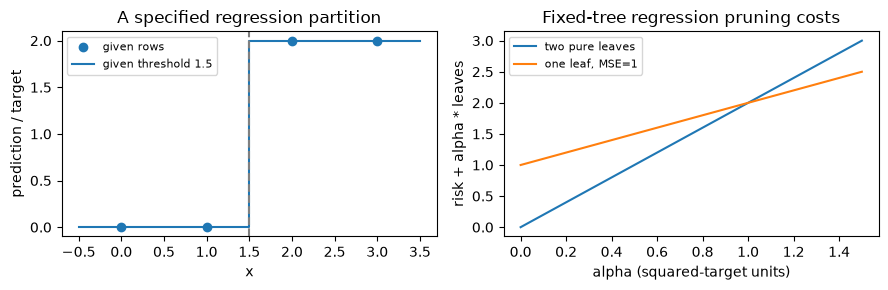

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
demo_x = np.array([0.,1.,2.,3.]); demo_y = np.array([0.,0.,2.,2.])
axes[0].scatter(demo_x, demo_y, label='given rows')
axes[0].plot([-.5,1.5,1.5,3.5], [0,0,2,2], label='given threshold 1.5')
axes[0].axvline(1.5, color='gray', linestyle='--')
axes[0].set(xlabel='x', ylabel='prediction / target', title='A specified regression partition')
axes[0].legend(fontsize=8)
demo_alpha = np.linspace(0, 1.5, 101)
demo_split_cost = 2*demo_alpha
demo_leaf_cost = 1+demo_alpha
axes[1].plot(demo_alpha, demo_split_cost, label='two pure leaves')
axes[1].plot(demo_alpha, demo_leaf_cost, label='one leaf, MSE=1')
axes[1].set(xlabel='alpha (squared-target units)', ylabel='risk + alpha * leaves', title='Fixed-tree regression pruning costs')
axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

### Exercise 02.04.11 — Compare growth and pruning under matched splits

**Type:** Experimental · **Answer:** Code

For seeds 215–217, generate independent training/validation sets of 120/160 rows, with $X$ uniform on $[-2,2]^2$ and target $\sin(2X_0)+.3X_1+\epsilon$, $\epsilon\sim\mathcal N(0,.2^2)$. Compare regression depths $(1,3,6)$ with `min_leaf=3`. Prune the same depth-six tree with $\alpha\in\{0,.005,.02,.1\}$. Report training/validation MSE, nodes/leaves/depth, elapsed time and paired seed variation. Keep a future final test set unused.

**Expected outcome:** actual measured records, a bounded candidate budget, and separate statements about training fit and validation generalization.

In [ ]:
# Your code for Exercise 02.04.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.04.11**

Generate each dataset once per seed. Different pruning penalties consume the same depth-six fitted tree.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.04.11**

This depends on fit/predict/size/prune references. The grid illustrates control choices without claiming an optimal universal depth or penalty. Validation can guide a later decision, but reusing it to publish a final unbiased test metric would be incorrect. Times include fitting, pruning and prediction for each candidate as indicated.

~~~python
from time import perf_counter

demo_tree_records = []
for seed in range(215, 218):
    rng = np.random.default_rng(seed)
    data = []
    for size in (120, 160):
        X = rng.uniform(-2, 2, size=(size,2))
        y = np.sin(2*X[:,0]) + .3*X[:,1] + rng.normal(0,.2,size)
        data.append((X,y))
    (train_X, train_y), (valid_X, valid_y) = data
    grown = None
    for depth in (1,3,6):
        started = perf_counter()
        model = fit_tree(train_X, train_y, 'mse', depth, min_leaf=3)
        train_p, _ = predict_tree(model, train_X)
        valid_p, _ = predict_tree(model, valid_X)
        demo_tree_records.append((seed, 'depth', depth, np.mean((train_p-train_y)**2),
                                  np.mean((valid_p-valid_y)**2), tree_size(model), perf_counter()-started))
        if depth == 6:
            grown = model
    for alpha in (0.,.005,.02,.1):
        started = perf_counter()
        model = prune_tree(grown, alpha)
        train_p, _ = predict_tree(model, train_X)
        valid_p, _ = predict_tree(model, valid_X)
        demo_tree_records.append((seed, 'alpha', alpha, np.mean((train_p-train_y)**2),
                                  np.mean((valid_p-valid_y)**2), tree_size(model), perf_counter()-started))
assert len(demo_tree_records) == 21
print('Measured tree validation records:', demo_tree_records)
~~~

</details>

### Exercise 02.04.12 — Measure sensitivity to a small training perturbation

**Type:** Experimental · **Answer:** Code

Using seed 218, generate 80 uniform $[-1,1]^2$ training rows with label $1[X_0+X_1>0]$ and flip four randomly selected labels. Fit a depth-four Gini tree with `min_leaf=2`. Fit a second tree after changing exactly one label. Compare predictions on the same 400-row independently generated probe set, sizes and root choices. Repeat for four distinct changed-label indices chosen before inspecting outcomes. Report disagreement rather than asserting it must be large.

**Expected outcome:** a controlled perturbation, actual disagreement rates, and limits on generalizing from one sample.

In [ ]:
# Your code for Exercise 02.04.12.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.04.12**

Freeze the probe observations and every growth rule. A change in data can alter the selected root and all descendant regions, but that need not happen for every index.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.04.12**

This depends on the classification tree references. Probe disagreement measures sensitivity for the declared perturbations; it is neither an uncertainty estimate nor an accuracy result unless probe labels and a population model are also used. The experiment does not invent a claim that each modified label necessarily changes the tree.

~~~python
demo_rng = np.random.default_rng(218)
demo_train_X = demo_rng.uniform(-1,1,size=(80,2))
demo_train_y = (demo_train_X.sum(axis=1) > 0).astype(int)
demo_train_y[demo_rng.choice(80,4,replace=False)] ^= 1
demo_probe_X = demo_rng.uniform(-1,1,size=(400,2))
demo_changes = demo_rng.choice(80,4,replace=False)
demo_original = fit_tree(demo_train_X, demo_train_y, max_depth=4, min_leaf=2)
demo_baseline, _ = predict_tree(demo_original, demo_probe_X)
demo_sensitivity = []
for index in demo_changes:
    changed = demo_train_y.copy(); changed[index] ^= 1
    altered = fit_tree(demo_train_X, changed, max_depth=4, min_leaf=2)
    predictions, _ = predict_tree(altered, demo_probe_X)
    demo_sensitivity.append((int(index), float(np.mean(predictions != demo_baseline)), tree_size(altered),
                             altered['root'].get('feature'), altered['root'].get('threshold')))
print('Measured one-label perturbations:', demo_sensitivity)
~~~

</details>

## 7. Interpretation and critical analysis

Tree rules are inspectable, but a short list of questions does not establish causality or stability. Numeric class labels are category names; numeric **feature** encodings can impose an arbitrary ordering on categories. Impurity reduction is an in-sample selection statistic and can favor features offering more candidate partitions. These limitations motivate controlled validation and the ensemble chapter, where averaging and reweighting change different parts of the procedure.

### Bounded primary-source study

Read [CS229 Decision Trees, §§1.2–1.5](https://cs229.stanford.edu/summer2023/cs229-notes-decision_trees.pdf). Focus on the weighted-gain equation, finite candidate partitions, regularization and the scope of a monotone-transformation statement. Translate one equation into the chapter's normalization and test an exact boundary case. The goal is a precise supported claim, not reproduction of all algorithms in the notes.

### Exercise 02.04.13 — Refine a monotone-transformation claim

**Type:** Critical · **Answer:** Markdown

Train a one-split classifier on $x=(0,2)$, labels $(0,1)$ using midpoint thresholds. Transform the numeric feature with the strictly increasing function $g(x)=x^3$ and refit under the same rules. Compare training partitions and the prediction for raw query $x=1.2$. State the invariance claim supported by this example and what stronger claim it refutes.

**Expected outcome:** identical training partitions but different query decisions, linked to how thresholds are represented between observations.

**Your response to Exercise 02.04.13**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.04.13**

The original threshold is $1$; the transformed threshold is $4$. Inverse-transforming $4$ does not give $1$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.04.13**

Both fits separate the two training rows perfectly. In raw space the midpoint rule routes $1.2>1$ right, predicting $1$. In transformed space the midpoint is $(0+8)/2=4$, and $1.2^3=1.728\le4$, predicting $0$. A strictly increasing transform preserves order and available training partitions in exact arithmetic, so the candidate impurity values correspond. It does not preserve every future-query prediction when midpoint thresholds are recomputed after a nonlinear transform. Transforming an already chosen threshold with $g$ would define a different implementation. Finite-precision ties can further limit even the training-order argument. Record this distinction in the paper-study template.

</details>

### Exercise 02.04.14 — Design an honest probability and importance audit

**Type:** Critical · **Answer:** Markdown

A deep tree has perfect training accuracy, several pure leaves, and high reported feature importance from total training impurity decrease. What evidence is missing before calling its probabilities reliable or its most-used feature causally important? Propose a bounded evaluation respecting the existing split protocol.

**Expected outcome:** calibration/proper-loss checks, a controlled importance comparison, leakage controls and a causal limitation.

**Your response to Exercise 02.04.14**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.04.14**

Zero leaf probabilities can yield infinite log loss on mistakes. Features with more split opportunities can gain selection advantages.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.04.14**

Inspect out-of-sample decision error and a proper probability metric such as Brier score, plus reliability summaries with sample counts. If adopting a smoothed leaf estimator, define its prior/normalization and choose settings within training/internal validation; report the forecast actually evaluated. Compare permutation effects on separate validation data while acknowledging correlated-feature and repeated-selection limitations. Use matched preprocessing and candidate budgets, and leave the final test unused until decisions are fixed. Training impurity decrease measures fit within a searched partition family; it is neither causal evidence nor a calibrated confidence interval. A causal conclusion requires assumptions and an identification design beyond this predictive experiment.

</details>

## 8. Review questions and knowledge checks

### Exercise 02.04.15 — Distinguish search criteria and evaluation metrics

**Type:** Numerical · **Answer:** Markdown

A node has empirical class probabilities $(.6,.3,.1)$. Compute zero-one impurity, Gini and entropy. Explain which optimal leaf outputs minimize each loss, whether their numerical values have interchangeable units, and why a minimum-Gini split need not minimize validation classification error.

**Expected outcome:** $.4$, $.54$, entropy approximately $.89794572$ nats, explicit minimizers, and a generalization limitation.

**Your response to Exercise 02.04.15**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.04.15**

Gini uses squared frequencies; entropy uses only positive frequencies inside logarithms.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.04.15**

Zero-one impurity is $1-.6=.4$ and is attained by choosing the first class. Gini is $1-(.36+.09+.01)=.54$ and minimizes the unscaled multiclass Brier expectation at the frequency vector. Entropy is $-.6\log.6-.3\log.3-.1\log.1\approx.8979457249$ nats and minimizes empirical log loss at that vector. These objective values differ in definition and units; penalty and gain settings must name the criterion. A split's in-sample probability-loss reduction does not imply minimum future zero-one error: the metric, selected partition and sampling error all matter.

</details>

### Exercise 02.04.16 — Present a tree mastery check

**Type:** Conceptual · **Answer:** Markdown

Explain the local/global normalization, repeated-value rule, greedy trap, stopping controls, fixed-tree pruning guarantee and probability limitations. Identify an independent split oracle, an exhaustive tiny pruning check, a controlled empirical comparison and a claim that remains unsupported.

**Expected outcome:** linked explanation, implementation, verification and evaluation evidence with a concrete remaining limitation.

**Your response to Exercise 02.04.16**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.04.16**

Separate a correct algorithmic result on the finite training sample from a statement about future data.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.04.16**

Local gain weights children within a node; global risk also weights the node by its training fraction. Equal feature values share a branch, and exhaustive one-step search can still stop before a useful deeper pattern. Depth, minimum leaf size and strictly positive minimum gain define the growth contract. At a fixed penalty, additive dynamic programming gives an optimal pruning of that grown tree, not an optimal tree over all partitions. Independent scalar split enumeration and exhaustive tiny subtree costs test the numerical contract. Matched validation and perturbation runs provide bounded empirical evidence. They do not establish causality, universal calibration, robustness to arbitrary shifts or a globally optimal partition search.

</details>

## 9. Summary and next learning steps

Decision trees connect loss minimization to discrete region search. Correct child weighting, explicit equality/tie rules, observed-value partitions and objective units make the result reproducible. Stopping and pruning control different stages of fitting, and both leave statistical questions for evaluation. The exact counterexamples show how to refine a research claim without confusing an implementation contract with a universal theorem.

Before advancing, produce your own leaf-risk derivations, both tree types, independent split and pruning checks, measured validation and sensitivity records, and the bounded reading audit. Next, tree ensembles compare bootstrap averaging and feature subsampling with sequential loss reduction. Return to the [stage guide](README.md) or [full learning path](../../README.md); later units remain explicitly planned until their gates pass.